# Quantum Fourier transform (QFT)

The discrete Fourier transform decomposes a sampled signal into its frequency components,

$$\tilde{x}_k=\frac{1}{\sqrt{N}}\sum_{j=0}^{N-1} x_j\,e^{2\pi i jk/N}. $$

The QFT performs the same transformation coherently on quantum amplitudes. On an $n$-qubit state it requires only $O(n^2)$ gates, compared with the classical $O(n2^n)$ cost. This notebook prepares a periodic signal as a quantum state and analyzes its spectrum with the QFT.

## Periodic test signal

The signal $x_j=\sin(2\pi kj/N)$ with integer frequency $k=4$ completes exactly four cycles over $N=32$ samples. Writing it as

$$\sin(2\pi kj/N)=\frac{e^{2\pi ikj/N}-e^{-2\pi ikj/N}}{2i}$$

shows that its Fourier spectrum has support only on the conjugate frequencies $k$ and $N-k$.

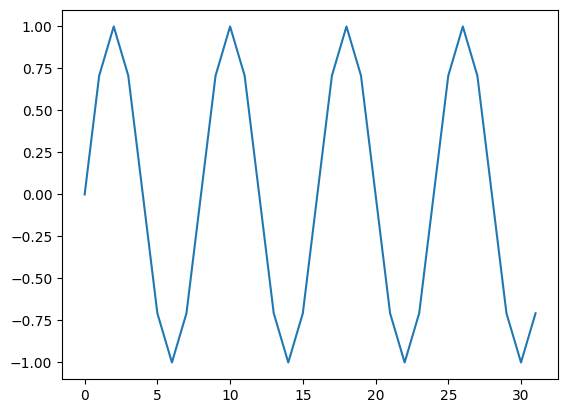

In [3]:
import matplotlib.pyplot as plt
import numpy as np


N = 2**5
k = 4

omega = 2 * np.pi * k / N

periodic_signal = np.sin([i * omega for i in range(N)])

plt.plot(periodic_signal)

## Amplitude encoding

A classical vector $x=(x_0,\ldots,x_{N-1})$ with $N=2^n$ entries can be encoded in the amplitudes of an $n$-qubit state,

$$|x\rangle=\frac{1}{\|x\|}\sum_{j=0}^{N-1} x_j\,|j\rangle. $$

The `initialize` instruction constructs a circuit preparing this normalized state. Only the normalized direction matters physically, since quantum states are defined up to normalization and a global phase.

In [4]:
import numpy as np
from qiskit import QuantumCircuit

def prepare_signal(signal):
    signal = np.asarray(signal, dtype=complex)

    n = int(np.log2(len(signal)))

    if len(signal) != 2**n:
        raise ValueError("Signal length must be a power of two.")

    norm = np.linalg.norm(signal)

    if norm == 0:
        raise ValueError("Signal cannot be zero.")

    amplitudes = signal / norm

    qc = QuantumCircuit(n)
    qc.initialize(amplitudes, range(n))

    return qc

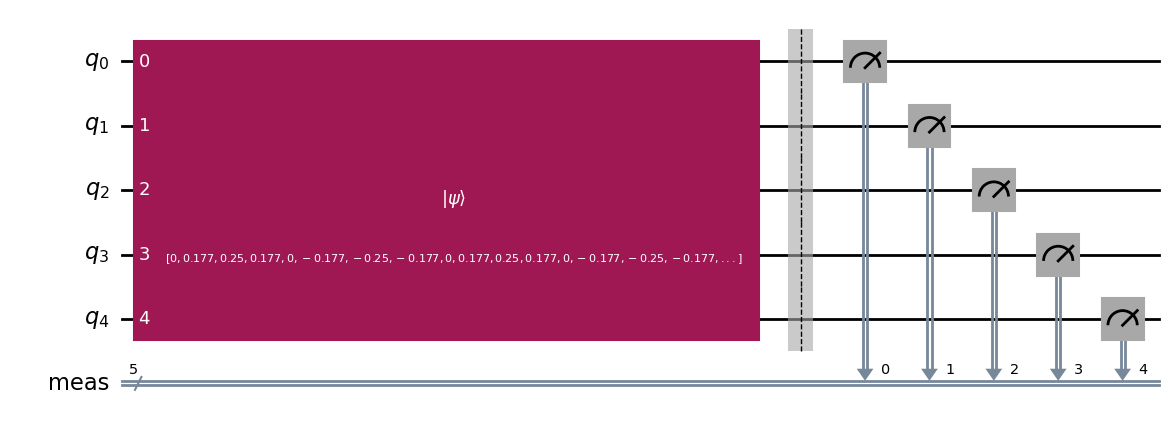

In [5]:
qc = prepare_signal(periodic_signal)
qc.measure_all()
qc.draw('mpl')

## Measurement probabilities

Measuring the encoded state yields index $j$ with probability $p_j=|x_j|^2/\|x\|^2$. The bar chart compares sampled probabilities with the analytic distribution $\sin^2(2\pi kj/N)/(N/2)$, which follows from the normalization identity $\sum_j\sin^2(2\pi kj/N)=N/2$ for $k\neq 0, N/2$.


$$
\sum_j \sin^2(2\pi kj/N)=\frac{N}{2}
$$

00001 1 0.03089
00010 2 0.0618
00011 3 0.03124
00101 5 0.03068
00110 6 0.06384
00111 7 0.03175
01001 9 0.03156
01010 10 0.0619
01011 11 0.03161
01101 13 0.03151
01110 14 0.0627
01111 15 0.03077
10001 17 0.03096
10010 18 0.06209
10011 19 0.03025
10101 21 0.03123
10110 22 0.06242
10111 23 0.03144
11001 25 0.03149
11010 26 0.06386
11011 27 0.03164
11101 29 0.03127
11110 30 0.0625
11111 31 0.0306


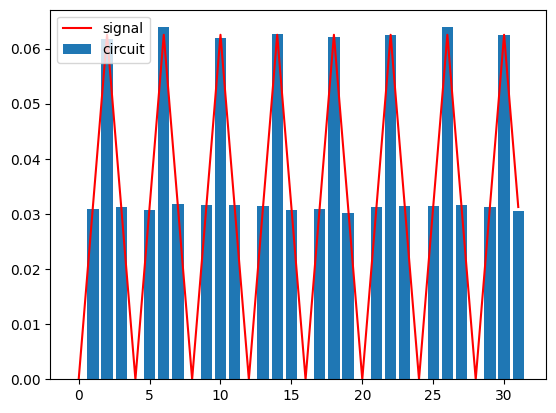

In [6]:
from qiskit.primitives import StatevectorSampler


sampler = StatevectorSampler()
result = sampler.run([qc], shots=100000).result()
counts = result[0].data.meas.get_counts()

counts_ordered = dict(sorted(counts.items(), key=lambda item: int(item[0], 2)))

values = np.zeros(2**qc.num_qubits)
for k, v in counts_ordered.items():
    bit_num = int(k, 2)
    print(k, bit_num, v/100000)
    values[bit_num] = v/100000

import matplotlib.pyplot as plt

plt.bar(range(2**qc.num_qubits), values, label='circuit')
plt.plot(range(2**qc.num_qubits), periodic_signal**2/N*2, color='red', label='signal')
plt.legend()


## Applying the QFT

The `QFTGate` implements the unitary

$$\mathrm{QFT}|j\rangle=\frac{1}{\sqrt{N}}\sum_{k=0}^{N-1}e^{2\pi ijk/N}|k\rangle. $$

Applying it to the signal state coherently computes all Fourier amplitudes at once. Measuring afterwards samples the squared Fourier coefficients $|\tilde{x}_k|^2$, the signal's power spectrum.

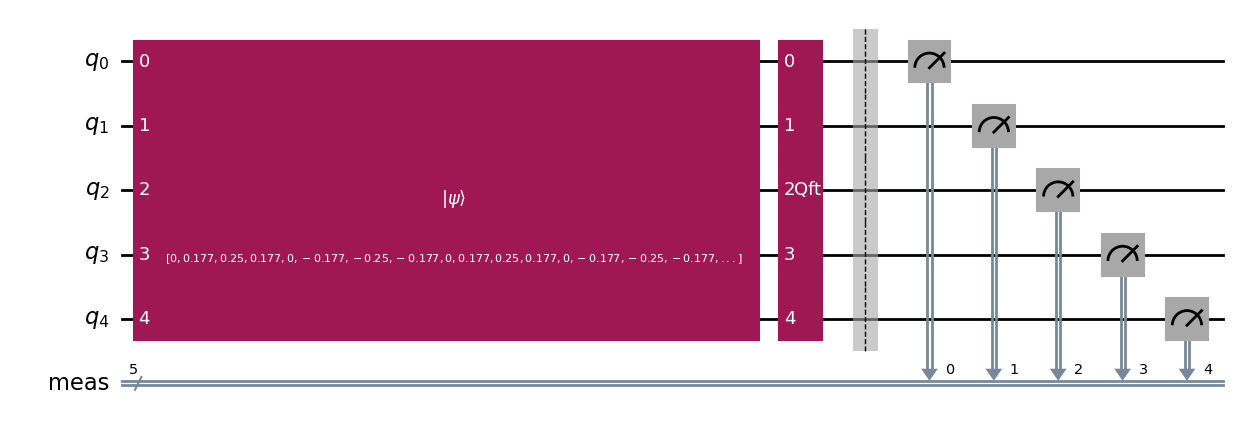

In [7]:
from qiskit.circuit.library import QFTGate


# Prepare the periodic state
qc_ft = prepare_signal(periodic_signal)

# Apply QFT
qc_ft.append(QFTGate(qc_ft.num_qubits), range(qc_ft.num_qubits))
qc_ft.measure_all()
qc_ft.draw('mpl')

## Sampling the Fourier spectrum

`StatevectorSampler` executes the circuit repeatedly and returns a histogram of measured bit strings. Each five-bit string is interpreted as an integer frequency index, so the counts at `00100` and `11100` correspond to frequencies 4 and 28. With a finite number of shots, the observed frequencies fluctuate around the ideal probabilities.

The histogram contains $|\tilde{x}_k|^2$, not the complex phase of $\tilde{x}_k$. Recovering phase information requires additional circuit design, such as interference with a reference state.

00100 4 0.50116
11100 28 0.49884


<BarContainer object of 32 artists>

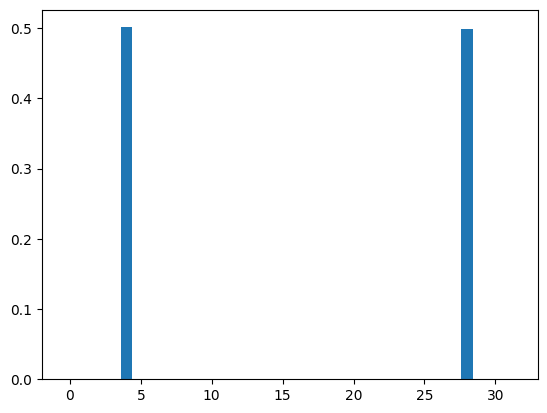

In [8]:
from qiskit.primitives import StatevectorSampler

sampler = StatevectorSampler()
result = sampler.run([qc_ft], shots=100000).result()
counts = result[0].data.meas.get_counts()
#print(counts)
counts_ordered = dict(sorted(counts.items(), key=lambda item: int(item[0], 2)))

n_states = 2**qc.num_qubits
values = np.zeros(n_states)

for k, v in counts_ordered.items():
    bit_num = int(k, 2)
    print(k, bit_num, v/100000)
    values[bit_num] = v/100000

import matplotlib.pyplot as plt

plt.bar(range(n_states), values)

## Interpreting the spectrum

The measured distribution concentrates at frequencies $k=4$ and $N-k=28$, exactly matching the two complex exponentials in the sine wave. The conjugate peak appears because a real signal has a symmetric spectrum.

This is the measurement-level signature used by quantum phase estimation: there the periodic signal is generated by unitary evolution, and the peak location encodes an eigenphase (and hence an energy eigenvalue).

## try yourself

- Change the value of the frequency and observe the results
- How can we obtain only one peak in the last plot?